Gerando um grafo de uma imagem em escala de cinza

---

Bibliotecas

In [130]:
import cv2

import matplotlib.pyplot as plt
import networkx          as nx
import numpy             as np


---

Carregando a imagem

In [131]:
josefran_image = cv2.imread("../assets/josefran.jpg")
josefran_image = cv2.cvtColor(josefran_image, cv2.COLOR_BGR2GRAY)

josefran_image.shape

(640, 640)

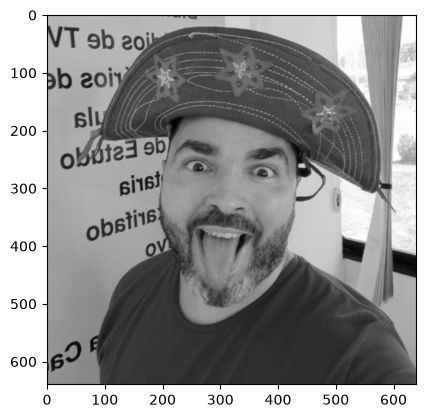

In [132]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

Redimensionando para $64\times64$

In [133]:
josefran_image = cv2.resize(josefran_image, (64, 64), cv2.INTER_LINEAR)
josefran_image.shape

(64, 64)

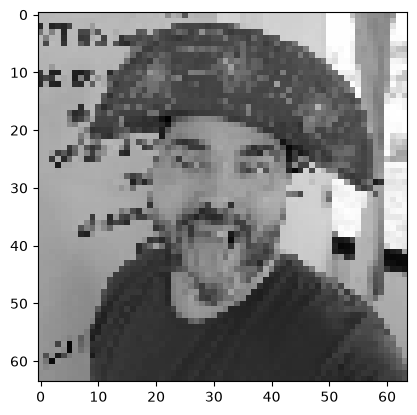

In [134]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

---

Gerando um grafo da imagem exemplo

In [135]:
def construir_grafo_imagem(matriz_pixels, vizinhanca=4, limiar=10):
    altura, largura = matriz_pixels.shape
    grafo           = { (i, j): [] for i in range(altura) for j in range(largura) }
    
    # Definir deslocamentos com base na vizinhança
    if vizinhanca == 4:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    elif vizinhanca == 8:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1), 
                    (-1, -1), (-1, 1), (1, -1), (1, 1)]
    else:
        raise ValueError("A vizinhança deve ser 4 ou 8.")

    for i in range(altura):
        for j in range(largura):
            u = (i, j)
            intensidade_u = matriz_pixels[i, j]
            
            for di, dj in direcoes:
                ni, nj = i + di, j + dj
                
                if 0 <= ni < altura and 0 <= nj < largura:
                    v = (ni, nj)
                    intensidade_v = matriz_pixels[ni, nj]
                    
                    if abs(int(intensidade_u) - int(intensidade_v)) <= limiar:
                        grafo[u].append(v)
                        
    return grafo

In [136]:
josefran_graph = construir_grafo_imagem(josefran_image)

---

Visualizando o grafo gerado

In [137]:
def plotar_grafo_imagem(matriz_pixels, grafo):
    
    # 1. Converter o dicionário de adjacência em um grafo do NetworkX
    G = nx.Graph()
    for u, vizinhos in grafo.items():
        for v in vizinhos:
            G.add_edge(u, v)
            
    # 2. Definir a posição espacial de cada nó (invertendo o eixo y para alinhar com a matriz de imagem)
    # Cada nó u é uma tupla (i, j) onde i é a linha e j é a coluna
    pos = {u: (u[1], -u[0]) for u in G.nodes()}
    
    # 3. Extrair a intensidade dos pixels para colorir os nós (opcional)
    nodos = list(G.nodes())
    cores = [matriz_pixels[u[0], u[1]] for u in nodos]
    
    # 4. Configurar e plotar
    plt.figure(figsize=(8, 8))
    nx.draw_networkx_nodes(
        G, pos, 
        nodelist=nodos, 
        node_size=1, 
        node_color=cores, 
        cmap=plt.cm.gray  
    )
    nx.draw_networkx_edges(
        G, pos, 
        width=0.5, 
        alpha=0.5, 
        edge_color='blue'
    )
    
    plt.title("Visualização do Grafo de Pixels")
    plt.axis('off')
    plt.show()

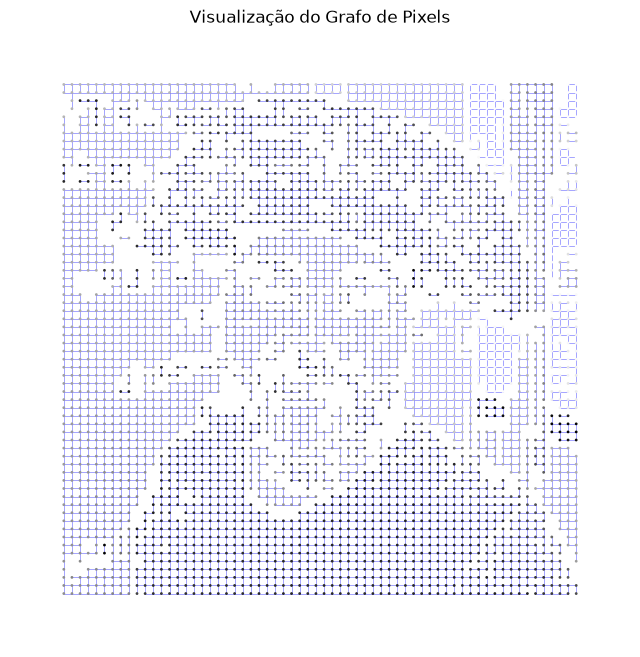

In [138]:
plotar_grafo_imagem(josefran_image, josefran_graph)